# Tarea 4 — Impacto económico de la campaña

easyMoney · TFM Nuclio Digital School

**Objetivo.** Traducir los modelos de la Tarea 2 y los grupos de la Tarea 3 en una decisión de negocio: **qué producto ofrecer, a cuántos clientes, a qué grupos y cuánto dinero se espera ganar**, con un rango de confianza.

**De dónde sale cada dato**

| Fichero | Lo genera | Para qué se usa aquí |
|---|---|---|
| `df_sales_limpio.parquet` | 01 Base común | Margen real de cada venta por producto |
| `scoring_{producto}.csv` | 02 Tarea 2 | Clientes a contactar en junio y su probabilidad |
| `validacion_{producto}.csv` | 02 Tarea 2 | Probabilidad y **compra real** de mayo → conversión medida, no supuesta |
| `clientes_grupos_abril.csv` | 03 Tarea 3 | Grupo de cada cliente **antes** de las compras de mayo (para medir sin trampas) |
| `clientes_grupos.csv` | 03 Tarea 3 | Grupo de cada cliente en mayo (para la campaña de junio) |

**Regla para no hacer trampas (leakage).** Toda conversión se **mide** en validación: probabilidad calculada con datos hasta abril, grupo de abril y compra real de mayo. Después se **aplica** a la lista de junio (scoring + grupo de mayo). Nunca se mezcla el grupo de mayo con las compras de mayo.

**Lo único que no sale de los datos** son los costes de campaña (celda siguiente). Por eso al final hay un análisis de sensibilidad: comprobamos si la recomendación cambia cuando cambian esos costes.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── Supuestos de negocio (únicos valores que no salen de los datos) ──────
COSTE_CONTACTO = 0.50      # € por cliente contactado: email + gestión de campaña
COSTE_FIJO     = 10000     # € de diseño, creatividad y horas de equipo
N_SIMULACIONES = 10000     # tiradas Monte Carlo
SEMILLA        = 42

rng = np.random.default_rng(SEMILLA)
pd.set_option('display.width', 200)

## 1. Carga de datos

Las ventas se leen de la **base común** (`df_sales_limpio.parquet`), no del CSV en bruto: así usamos exactamente las mismas ventas que en las tareas 2 y 3 (solo clientes del panel y sin meses de fallecidos). `product_description.csv` solo se usa para poner nombre a cada `product_ID`.

In [2]:
ruta_raw  = "../data/raw/"
ruta_proc = "../data/processed/"

df_sal = pd.read_parquet(ruta_proc + "df_sales_limpio.parquet")
df_prd = pd.read_csv(ruta_raw + "product_description.csv", index_col=0)

scoring_pp   = pd.read_csv(ruta_proc + "scoring_pension_plan.csv")
scoring_em   = pd.read_csv(ruta_proc + "scoring_em_acount.csv")
grupos       = pd.read_csv(ruta_proc + "clientes_grupos.csv")          # grupo de mayo  → campaña de junio
grupos_abril = pd.read_csv(ruta_proc + "clientes_grupos_abril.csv")    # grupo de abril → medir con compras de mayo

print("Ventas:", df_sal.shape)
print("Scoring pension_plan:", scoring_pp.shape)
print("Scoring em_acount:", scoring_em.shape)
print("Grupos mayo:", grupos.shape, "| Grupos abril:", grupos_abril.shape)

Ventas: (240752, 5)
Scoring pension_plan: (425556, 3)
Scoring em_acount: (146575, 3)
Grupos mayo: (442909, 3) | Grupos abril: (439543, 3)


## 2. ¿Cuánto deja cada venta?

Margen neto medio por producto a partir de las ventas reales. Esto explica por qué la campaña se centra en `pension_plan`: cada venta deja mucho más que una `em_acount`.

In [3]:
margen_prod = (df_sal.merge(df_prd, left_on="product_ID", right_on="pk_product_ID", how="left")
               .groupby(["product_ID", "product_desc"])
               .agg(ventas=("pk_sale", "count"),
                    margen_medio=("net_margin", "mean"),
                    margen_mediano=("net_margin", "median"),
                    margen_std=("net_margin", "std"),
                    margen_total=("net_margin", "sum"))
               .round(1)
               .sort_values("margen_total", ascending=False))

margen_prod["pct_margen_total"] = (margen_prod["margen_total"] / margen_prod["margen_total"].sum() * 100).round(1)
print(margen_prod)

                               ventas  margen_medio  margen_mediano  margen_std  margen_total  pct_margen_total
product_ID product_desc                                                                                        
1364       pension_plan         19368        5976.3          5640.8      2215.9   115749834.9              79.2
4657       em_acount           117425          70.0            70.0        10.0     8216725.5               5.6
2335       short_term_deposit    4441        1486.4          1414.0       443.0     6601241.5               4.5
2336       long_term_deposit     4227        1496.9          1431.8       449.6     6327477.4               4.3
3819       debit_card           38837          60.0            60.0         5.0     2330337.3               1.6
2673       securities            1157        1497.8          1435.7       446.6     1732993.2               1.2
1119       funds                  880        1499.0          1432.4       464.4     1319161.5           

In [4]:
# Productos de la campaña: margen medio (para el cálculo directo) y la lista de márgenes reales
# de cada venta (para muestrear en la simulación Monte Carlo).
PRODUCTOS = {
    "pension_plan": {"id": 1364, "scoring": scoring_pp, "col_prob": "probabilidad_pension_plan"},
    "em_acount":    {"id": 4657, "scoring": scoring_em, "col_prob": "probabilidad_em_acount"},
}

for nombre, p in PRODUCTOS.items():
    margenes = df_sal.loc[df_sal["product_ID"] == p["id"], "net_margin"].values
    p["margen_medio"] = margenes.mean()
    p["margenes"]     = margenes
    print(f"{nombre:13s} | margen medio {p['margen_medio']:8.1f} € | {len(margenes):,} ventas reales para muestrear")

pension_plan  | margen medio   5976.3 € | 19,368 ventas reales para muestrear
em_acount     | margen medio     70.0 € | 117,425 ventas reales para muestrear


## 3. Curva de conversión real (validación)

Ordena a los clientes de mayo por su nota y mide cuántos compraron de verdad si llamas al 1 %, 2 %, 5 %, 10 %… mejor. Datos clave del plan de pensiones:

In [5]:
def curva_conversion(df_val, cortes=(1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50, 75, 100)):
    # Conversión real acumulada si contactamos al top X% de clientes por probabilidad.
    df = df_val.sort_values("probabilidad", ascending=False).reset_index(drop=True)
    tasa_base = df["compra_real"].mean()
    filas = []
    for pct in cortes:
        n = int(len(df) * pct / 100)
        top = df.iloc[:n]
        compras = int(top["compra_real"].sum())
        conv = compras / n
        filas.append({
            "top_pct": pct,
            "clientes": n,
            "compras": compras,
            "conversion_pct": round(conv * 100, 2),
            "lift": round(conv / tasa_base, 1),
            "pct_compras_capturadas": round(compras / df["compra_real"].sum() * 100, 1),
        })
    return pd.DataFrame(filas), tasa_base

for nombre, p in PRODUCTOS.items():
    val = pd.read_csv(ruta_proc + f"validacion_{nombre}.csv")
    p["validacion"] = val
    p["curva"], p["tasa_base"] = curva_conversion(val)
    print(f"\n{'='*60}\n{nombre}  |  tasa base {p['tasa_base']*100:.2f}%  |  {len(val):,} clientes en validación")
    print(p["curva"].to_string(index=False))


pension_plan  |  tasa base 0.66%  |  422,104 clientes en validación
 top_pct  clientes  compras  conversion_pct  lift  pct_compras_capturadas
       1      4221      682           16.16  24.4                    24.4
       2      8442     1208           14.31  21.6                    43.3
       3     12663     1471           11.62  17.6                    52.7
       5     21105     1775            8.41  12.7                    63.6
       7     29547     1913            6.47   9.8                    68.5
      10     42210     2070            4.90   7.4                    74.2
      15     63315     2267            3.58   5.4                    81.2
      20     84420     2391            2.83   4.3                    85.7
      30    126631     2460            1.94   2.9                    88.1
      40    168841     2626            1.56   2.4                    94.1
      50    211052     2689            1.27   1.9                    96.3
      75    316578     2752            0.87

## 4. Beneficio si solo usamos el modelo (top X%)

Coge la conversión que se midió de verdad en mayo (sección 3) y la aplica a los 425.556 clientes de junio, para estimar ventas, ingresos, costes y beneficio.

- **ventas** = clientes contactados × conversión real del corte
- **ingreso** = ventas × margen medio
- **coste** = clientes × coste por contacto + coste fijo
- **marginal**: qué aporta cada tramo añadido respecto al anterior y cuánto podrías pagar por contacto en ese tramo sin perder dinero 'breakeven_coste'

In [6]:
def tabla_beneficio(p, coste_contacto=COSTE_CONTACTO, coste_fijo=COSTE_FIJO):
    n_elegibles = len(p["scoring"])
    t = p["curva"][["top_pct", "conversion_pct", "lift"]].copy()
    t["clientes"]   = (n_elegibles * t["top_pct"] / 100).astype(int)
    t["ventas"]     = (t["clientes"] * t["conversion_pct"] / 100).round(0).astype(int)
    t["ingreso"]    = (t["ventas"] * p["margen_medio"]).round(0)
    t["coste"]      = (t["clientes"] * coste_contacto + coste_fijo).round(0)
    t["beneficio"]  = t["ingreso"] - t["coste"]
    t["roi"]        = (t["beneficio"] / t["coste"]).round(1)
    # Marginal: qué aporta el tramo añadido respecto al corte anterior
    t["ventas_marg"]     = t["ventas"].diff().fillna(t["ventas"]).astype(int)
    t["clientes_marg"]   = t["clientes"].diff().fillna(t["clientes"]).astype(int)
    t["conv_marg_pct"]   = (t["ventas_marg"] / t["clientes_marg"] * 100).round(2)
    t["breakeven_coste"] = (t["conv_marg_pct"] / 100 * p["margen_medio"]).round(2)
    return t

for nombre, p in PRODUCTOS.items():
    p["beneficio"] = tabla_beneficio(p)
    print(f"\n{'='*70}\n{nombre}  |  {len(p['scoring']):,} elegibles  |  margen {p['margen_medio']:.0f} €  |  coste contacto {COSTE_CONTACTO} €")
    print(p["beneficio"].to_string(index=False))


pension_plan  |  425,556 elegibles  |  margen 5976 €  |  coste contacto 0.5 €
 top_pct  conversion_pct  lift  clientes  ventas    ingreso    coste  beneficio   roi  ventas_marg  clientes_marg  conv_marg_pct  breakeven_coste
       1           16.16  24.4      4255     688  4111725.0  12128.0  4099597.0 338.0          688           4255          16.17           966.37
       2           14.31  21.6      8511    1218  7279187.0  14256.0  7264931.0 509.6          530           4256          12.45           744.05
       3           11.62  17.6     12766    1483  8862918.0  16383.0  8846535.0 540.0          265           4255           6.23           372.33
       5            8.41  12.7     21277    1789 10691680.0  20638.0 10671042.0 517.1          306           8511           3.60           215.15
       7            6.47   9.8     29788    1927 11516415.0  24894.0 11491521.0 461.6          138           8511           1.62            96.82
      10            4.90   7.4     42555    2

**Lectura.** Con un coste de 50 céntimos, el cálculo dice que compensa llamar a todos. Pero los últimos contactos compran uno de cada 3.300: si cada contacto costara más de 1,79 € (una carta ya cuesta 2 €), perderíamos dinero con ellos. Además, el cálculo no recoge el coste de molestar a clientes que no van a comprar ni la capacidad del equipo comercial. Por eso no buscamos el máximo teórico, sino dónde deja de compensar ampliar.

## 5. Cruce segmentación × propensión

Dos preguntas distintas, cada una con su foto de grupos:

- **a) ¿Qué grupos compran de verdad?** → validación (compras de mayo) × grupo de **abril**.
- **b) ¿A quién estaríamos contactando?** → scoring de junio × grupo de **mayo**.

In [7]:
def cruce_grupos(p, corte_pct):
    val = p["validacion"].merge(grupos_abril, on="pk_cid", how="left")
    val["nombre_grupo"] = val["nombre_grupo"].fillna("Sin grupo")
    umbral = val["probabilidad"].quantile(1 - corte_pct / 100)
    val["en_top"] = val["probabilidad"] >= umbral
    por_grupo = (val.groupby("nombre_grupo")
                 .agg(clientes=("pk_cid", "count"),
                      compras=("compra_real", "sum"),
                      conversion_pct=("compra_real", lambda s: round(s.mean() * 100, 2)),
                      pct_en_top=("en_top", lambda s: round(s.mean() * 100, 1)))
                 .sort_values("conversion_pct", ascending=False))
    por_grupo["pct_de_las_compras"] = (por_grupo["compras"] / por_grupo["compras"].sum() * 100).round(1)

    sc = p["scoring"].merge(grupos, on="pk_cid", how="left")
    sc["nombre_grupo"] = sc["nombre_grupo"].fillna("Sin grupo")
    n_top = int(len(sc) * corte_pct / 100)
    top = sc.nlargest(n_top, p["col_prob"])
    composicion = top["nombre_grupo"].value_counts().rename("clientes_en_top").to_frame()
    composicion["pct_del_top"] = (composicion["clientes_en_top"] / n_top * 100).round(1)
    return por_grupo, composicion

for nombre in PRODUCTOS:
    por_grupo, composicion = cruce_grupos(PRODUCTOS[nombre], 30)
    PRODUCTOS[nombre]["por_grupo"] = por_grupo
    print(f"\n{'='*70}\n{nombre} — conversión por grupo (grupo de abril, compra de mayo)")
    print(por_grupo.to_string())
    print(f"\n{nombre} — composición del top 30% del scoring (grupo de mayo)")
    print(composicion.to_string())


pension_plan — conversión por grupo (grupo de abril, compra de mayo)
                                clientes  compras  conversion_pct  pct_en_top  pct_de_las_compras
nombre_grupo                                                                                     
Particulares con nómina             5326      915           17.18        98.1                32.8
Universitarios con nómina           3844      510           13.27        99.1                18.3
Particulares con tarjeta           18724      329            1.76        98.7                11.8
Particulares básicos               51956      407            0.78        47.3                14.6
TOP ahorradores                    17444      104            0.60        64.0                 3.7
Universitarios recién llegados     65077      217            0.33        21.3                 7.8
Sin producto                      108821      126            0.12        38.1                 4.5
Universitarios inactivos          150912      18

**Lectura.** Tres grupos pequeños concentran casi dos tercios de las compras: Particulares con nómina (17,2 % de conversión), Universitarios con nómina (13,3 %) y Particulares con tarjeta (1,8 %). Entre los tres son unos 28.000 clientes, el 7 % de los que no tienen plan, y reúnen el 63 % de las compras de mayo. En estos grupos el modelo y la segmentación coinciden: el 98–99 % de sus clientes ya están en el top 30 % del modelo.

En el otro extremo, Universitarios recién llegados, Universitarios inactivos y Sin producto son el 77 % de los clientes sin plan y convierten como mucho un 0,33 %.

El problema aparece al usar solo el modelo: en su top 30 % (127.666 clientes), los tres grupos que más compran son solo el 22 % de los contactos. El 78 % restante son clientes de grupos que convierten poco, como Particulares básicos (30 % del top), Universitarios inactivos (18 %) o Universitarios recién llegados (13 %). El modelo pone arriba a los buenos compradores, pero al cortar en el 30 % arrastra a muchos clientes que casi no compran.

Esto justifica combinar las dos herramientas: llamar a todos los clientes de los grupos que más compran, no llamar a los grupos que casi no compran y usar la nota solo para elegir dentro de los grupos intermedios (secciones 6 a 8).

## 6. Clasificar los grupos para la campaña de `pension_plan`

En vez de escribir a mano qué grupos entran (los nombres y números de grupo cambian cada vez que se reentrena el K-Means), los clasificamos con una regla basada en la **conversión real de validación** frente a la tasa base del producto:

| Papel | Regla | Qué hacemos |
|---|---|---|
| **Núcleo** | convierte ≥ 2 × la tasa base y tiene al menos `MIN_COMPRAS` compras | Se contacta al grupo completo |
| **Excluido** | convierte < 0,5 × la tasa base | No se contacta |
| **Intermedio** | el resto | Solo se contacta a los de mayor probabilidad según el modelo |

`MIN_COMPRAS` evita que un grupo muy pequeño entre en el núcleo por casualidad. "Sin grupo" (clientes sin grupo asignado) siempre queda fuera.

In [8]:
FACTOR_NUCLEO  = 2.0   # núcleo: conversión ≥ 2 × tasa base
FACTOR_EXCLUIR = 0.5   # excluido: conversión < 0,5 × tasa base
MIN_COMPRAS    = 30    # compras mínimas en validación para entrar en el núcleo

p = PRODUCTOS["pension_plan"]
pg = p["por_grupo"].copy()
tasa = p["tasa_base"] * 100

def papel(fila):
    if fila.name == "Sin grupo":
        return "excluido"
    if fila["conversion_pct"] >= FACTOR_NUCLEO * tasa and fila["compras"] >= MIN_COMPRAS:
        return "núcleo"
    if fila["conversion_pct"] < FACTOR_EXCLUIR * tasa:
        return "excluido"
    return "intermedio"

pg["papel"] = pg.apply(papel, axis=1)
NUCLEO     = pg.index[pg["papel"] == "núcleo"].tolist()
INTERMEDIO = pg.index[pg["papel"] == "intermedio"].tolist()
EXCLUIR    = pg.index[pg["papel"] == "excluido"].tolist()

print(f"Tasa base pension_plan: {tasa:.2f}%  →  núcleo ≥ {FACTOR_NUCLEO*tasa:.2f}%  |  excluido < {FACTOR_EXCLUIR*tasa:.2f}%\n")
print(pg[["clientes", "compras", "conversion_pct", "pct_de_las_compras", "papel"]].to_string())
print("\nNúcleo:    ", NUCLEO)
print("Intermedio:", INTERMEDIO)
print("Excluidos: ", EXCLUIR)
assert NUCLEO, "Ningún grupo cumple la regla de núcleo: revisa FACTOR_NUCLEO / MIN_COMPRAS"

Tasa base pension_plan: 0.66%  →  núcleo ≥ 1.32%  |  excluido < 0.33%

                                clientes  compras  conversion_pct  pct_de_las_compras       papel
nombre_grupo                                                                                     
Particulares con nómina             5326      915           17.18                32.8      núcleo
Universitarios con nómina           3844      510           13.27                18.3      núcleo
Particulares con tarjeta           18724      329            1.76                11.8      núcleo
Particulares básicos               51956      407            0.78                14.6  intermedio
TOP ahorradores                    17444      104            0.60                 3.7  intermedio
Universitarios recién llegados     65077      217            0.33                 7.8    excluido
Sin producto                      108821      126            0.12                 4.5    excluido
Universitarios inactivos          150912      1

Lectura. Con una tasa base del 0,66 %, la regla clasifica como núcleo a Particulares con nómina (17,2 %), Universitarios con nómina (13,3 %) y Particulares con tarjeta (1,8 %): todos compran más del doble de la media y tienen más de 300 compras. Particulares básicos (0,8 %) y TOP ahorradores (0,6 %) quedan como intermedios. Universitarios recién llegados (0,33 %, justo en el límite), Universitarios inactivos y Sin producto (0,12 %) quedan excluidos. La clasificación sale de las compras reales de mayo, no de una decisión manual, y se recalcula sola si cambian los grupos.

## 7. Comparación de estrategias

- **A. Núcleo**: solo los grupos núcleo, completos (tarea 3).
- **B. Ampliada**: núcleo + intermedios, completos.
- **C. Solo modelo**: top 30% del scoring, sin mirar grupos (tarea 2).
- **D. Híbrida**: núcleo completo + top X% del modelo dentro de los intermedios (sección 8).

Para A y B, ventas esperadas = Σ (clientes del grupo en junio × conversión del grupo en validación).

Para C se coge directamente la fila del 30 % de la tabla de la sección 4.

El dinero, igual para todas:

ingreso = ventas × 5.976 €
coste = contactos × 0,50 € + 10.000 €
beneficio = ingreso − coste

In [9]:
conv_grupo = pg["conversion_pct"] / 100

sc = p["scoring"].merge(grupos, on="pk_cid", how="left")
sc["nombre_grupo"] = sc["nombre_grupo"].fillna("Sin grupo")

ESTRATEGIAS = {
    "A. Núcleo":   NUCLEO,
    "B. Ampliada": NUCLEO + INTERMEDIO,
}

filas = []
for nombre_est, lista in ESTRATEGIAS.items():
    sel = sc[sc["nombre_grupo"].isin(lista)]
    ventas = sum((sel["nombre_grupo"] == g).sum() * conv_grupo.get(g, 0) for g in lista)
    filas.append({"estrategia": nombre_est, "contactos": len(sel), "ventas": round(ventas)})

fila_c = p["beneficio"].loc[p["beneficio"]["top_pct"] == 30].iloc[0]
filas.append({"estrategia": "C. Top 30% modelo", "contactos": int(fila_c["clientes"]), "ventas": int(fila_c["ventas"])})

comp = pd.DataFrame(filas)
comp["conversion_pct"] = (comp["ventas"] / comp["contactos"] * 100).round(2)
comp["ingreso"]   = (comp["ventas"] * p["margen_medio"]).round(0)
comp["coste"]     = (comp["contactos"] * COSTE_CONTACTO + COSTE_FIJO).round(0)
comp["beneficio"] = comp["ingreso"] - comp["coste"]
comp["roi"]       = (comp["beneficio"] / comp["coste"]).round(0)
comp["beneficio_por_contacto"] = (comp["beneficio"] / comp["contactos"]).round(0)
print(comp.to_string(index=False))

       estrategia  contactos  ventas  conversion_pct    ingreso   coste  beneficio   roi  beneficio_por_contacto
        A. Núcleo      28464    1766            6.20 10554224.0 24232.0 10529992.0 435.0                   370.0
      B. Ampliada      97606    2272            2.33 13578254.0 58803.0 13519451.0 230.0                   139.0
C. Top 30% modelo     127666    2477            1.94 14803405.0 73833.0 14729572.0 199.0                   115.0


Lectura. Llamar solo al núcleo (A) es lo más eficiente: 6,2 % de conversión y 370 € de beneficio por contacto, pero se queda en 1.766 ventas. Ampliar a los intermedios completos (B) o usar solo el modelo (C) añade ventas, pero cada contacto nuevo rinde mucho menos: de A a B solo compra un 0,7 % de los clientes añadidos, y de B a C otro 0,7 %. El beneficio por contacto cae de 370 € a 139 € y 115 €. Ninguna de las tres combina eficiencia y volumen: A no aprovecha el modelo y C no aprovecha los grupos. La estrategia D (sección 8) junta las dos: el núcleo completo y la nota solo para elegir dentro de los intermedios.

## 8. Estrategia D (híbrida)

Núcleo completo + top X% del modelo **solo dentro de los grupos intermedios**. Los excluidos nunca se contactan.

La regla se aplica primero en validación (grupo de abril, compra de mayo) para **medir** su conversión, y después en el scoring (grupo de mayo) para saber **a cuántos** contactar en junio. Probamos varios X para ver dónde deja de compensar ampliar.

In [10]:
def aplicar_regla(df, col_prob, col_grupo, top_pct_resto):
    umbral = df[col_prob].quantile(1 - top_pct_resto / 100)
    en_nucleo = df[col_grupo].isin(NUCLEO)
    en_resto  = df[col_grupo].isin(INTERMEDIO) & (df[col_prob] >= umbral)
    return df[en_nucleo | en_resto]

val = p["validacion"].merge(grupos_abril, on="pk_cid", how="left")
val["nombre_grupo"] = val["nombre_grupo"].fillna("Sin grupo")

filas = []
for top_resto in [0, 5, 10, 15, 20, 30]:
    v = aplicar_regla(val, "probabilidad", "nombre_grupo", top_resto)
    conv = v["compra_real"].mean()
    s = aplicar_regla(sc, p["col_prob"], "nombre_grupo", top_resto)
    filas.append({"top_resto_pct": top_resto, "contactos": len(s),
                  "conversion_pct": round(conv * 100, 2), "ventas": round(len(s) * conv),
                  "pct_compras_capturadas": round(v["compra_real"].sum() / val["compra_real"].sum() * 100, 1)})

hib = pd.DataFrame(filas)
hib["ingreso"]   = (hib["ventas"] * p["margen_medio"]).round(0)
hib["coste"]     = (hib["contactos"] * COSTE_CONTACTO + COSTE_FIJO).round(0)
hib["beneficio"] = hib["ingreso"] - hib["coste"]
hib["beneficio_por_contacto"] = (hib["beneficio"] / hib["contactos"]).round(0)
# Qué aporta cada ampliación respecto a la fila anterior
hib["beneficio_extra"] = hib["beneficio"].diff()
hib["contactos_extra"] = hib["contactos"].diff()
print(hib.to_string(index=False))

 top_resto_pct  contactos  conversion_pct  ventas  pct_compras_capturadas    ingreso   coste  beneficio  beneficio_por_contacto  beneficio_extra  contactos_extra
             0      28464            6.28    1788                    63.0 10685703.0 24232.0 10661471.0                   375.0              NaN              NaN
             5      36574            5.28    1932                    71.8 11546297.0 28287.0 11518010.0                   315.0         856539.0           8110.0
            10      40178            4.90    1970                    72.8 11773398.0 30089.0 11743309.0                   292.0         225299.0           3604.0
            15      51046            4.09    2086                    76.1 12466654.0 35523.0 12431131.0                   244.0         687822.0          10868.0
            20      62220            3.70    2299                    76.7 13739615.0 41110.0 13698505.0                   220.0        1267374.0          11174.0
            30      82469   

**Elección del corte.** Elegimos X = 20 % (TOP_RESTO). La columna de beneficio sigue subiendo con X más altos, pero no refleja bien lo que pasa: aplica la conversión media de toda la selección a los contactos añadidos, que compran mucho menos. La columna pct_compras_capturadas, medida con compras reales de mayo, muestra que a partir del 15–20 % ampliar casi no encuentra compradores nuevos: de 20 a 30 % solo sube de 76,7 % a 77,9 %, con más de 20.000 contactos extra en junio. El 20 % es un compromiso entre volumen de ventas y no saturar a clientes que probablemente no comprarán. El corte se puede cambiar en el simulador

In [11]:
TOP_RESTO = 20   # % del modelo dentro de los grupos intermedios en la estrategia recomendada

hib_a = hib.loc[hib["top_resto_pct"] == 0].iloc[0]
hib_d = hib.loc[hib["top_resto_pct"] == TOP_RESTO].iloc[0]
print(f"A. Núcleo        : {int(hib_a['contactos']):>7,} contactos | {int(hib_a['ventas']):,} ventas | {hib_a['beneficio']/1e6:.2f} M€")
print(f"D. Híbrida {TOP_RESTO}%  : {int(hib_d['contactos']):>7,} contactos | {int(hib_d['ventas']):,} ventas | {hib_d['beneficio']/1e6:.2f} M€")
print(f"C. Top 30% modelo: {int(fila_c['clientes']):>7,} contactos | {int(fila_c['ventas']):,} ventas | {fila_c['beneficio']/1e6:.2f} M€")

A. Núcleo        :  28,464 contactos | 1,788 ventas | 10.66 M€
D. Híbrida 20%  :  62,220 contactos | 2,299 ventas | 13.70 M€
C. Top 30% modelo: 127,666 contactos | 2,477 ventas | 14.73 M€


## 9. Monte Carlo: ¿cuánto podemos fiarnos del beneficio?

El beneficio calculado arriba es una estimación puntual. Hay dos fuentes de incertidumbre:

1. **La conversión**: la medimos sobre un mes. Se modela con una distribución Beta(compras + 1, no compras + 1).
2. **El margen de cada venta**: no todas las ventas dejan lo mismo. Se muestrea de los márgenes reales.

Repetimos la campaña 10.000 veces y comunicamos el intervalo del 90% (percentiles 5 y 95).

In [12]:
def monte_carlo(p, regla_val, regla_sc, n_sim=N_SIMULACIONES):
    compras    = int(regla_val["compra_real"].sum())
    no_compras = len(regla_val) - compras
    contactos  = len(regla_sc)
    coste      = contactos * COSTE_CONTACTO + COSTE_FIJO
    resultados = np.empty(n_sim)
    for i in range(n_sim):
        conv    = rng.beta(compras + 1, no_compras + 1)
        ventas  = rng.binomial(contactos, conv)
        ingreso = rng.choice(p["margenes"], size=ventas).sum()
        resultados[i] = ingreso - coste
    return resultados, contactos

RESULTADOS_MC = {}
for etiqueta, top_resto in [("A. Núcleo", 0), (f"D. Híbrida {TOP_RESTO}%", TOP_RESTO)]:
    v = aplicar_regla(val, "probabilidad", "nombre_grupo", top_resto)
    s = aplicar_regla(sc,  p["col_prob"],  "nombre_grupo", top_resto)
    res, contactos = monte_carlo(p, v, s)
    RESULTADOS_MC[etiqueta] = res
    p5, p50, p95 = np.percentile(res, [5, 50, 95])
    print(f"{etiqueta:16s} | {contactos:>7,} contactos | "
          f"conservador {p5/1e6:5.2f} M€ | base {p50/1e6:5.2f} M€ | optimista {p95/1e6:5.2f} M€ | "
          f"P(beneficio < 0) = {(res < 0).mean():.1%}")

A. Núcleo        |  28,464 contactos | conservador 10.08 M€ | base 10.66 M€ | optimista 11.26 M€ | P(beneficio < 0) = 0.0%
D. Híbrida 20%   |  62,220 contactos | conservador 13.03 M€ | base 13.71 M€ | optimista 14.40 M€ | P(beneficio < 0) = 0.0%


Lectura. Con 10.000 simulaciones, la estrategia híbrida deja entre 13,0 y 14,4 M€ en el 90 % de los casos (mediana 13,7 M€), y en ninguna simulación se pierde dinero. El rango es estrecho porque la conversión se mide sobre decenas de miles de clientes y la variación del margen se compensa al sumar unas 2.300 ventas. Este intervalo solo recoge la incertidumbre de la muestra: no incluye que el mes de la campaña se comporte distinto de mayo, las ventas que se habrían producido sin campaña ni cambios en los costes supuestos. Por eso la cifra se presenta como orientativa.

## 10. Sensibilidad al coste por contacto

El coste por contacto es un supuesto. ¿Cambia la recomendación si el canal es más caro (carta, llamada, visita)? El **break-even** de la ampliación A → D es lo máximo que podemos pagar por cada contacto extra sin perder dinero.

In [13]:
conv_ext = (hib_d["ventas"] - hib_a["ventas"]) / max(hib_d["contactos"] - hib_a["contactos"], 1)
print(f"Ampliación A → D: {int(hib_d['contactos'] - hib_a['contactos']):,} contactos, "
      f"{int(hib_d['ventas'] - hib_a['ventas'])} ventas, conversión {conv_ext*100:.2f}% "
      f"→ break-even {conv_ext * p['margen_medio']:.0f} € por contacto\n")

CANALES = {0.10: "push/email", 0.50: "email + gestión", 2: "carta", 5: "llamada",
           10: "llamada larga", 30: "visita", 60: "visita + regalo"}
filas = []
for coste, canal in CANALES.items():
    ben_a = hib_a["ventas"] * p["margen_medio"] - (hib_a["contactos"] * coste + COSTE_FIJO)
    ben_d = hib_d["ventas"] * p["margen_medio"] - (hib_d["contactos"] * coste + COSTE_FIJO)
    filas.append({"coste_contacto": coste, "canal": canal,
                  "beneficio_A": round(ben_a / 1e6, 2), "beneficio_D": round(ben_d / 1e6, 2),
                  "mejor": "D" if ben_d > ben_a else "A"})
print(pd.DataFrame(filas).to_string(index=False))

Ampliación A → D: 33,756 contactos, 511 ventas, conversión 1.51% → break-even 90 € por contacto

 coste_contacto           canal  beneficio_A  beneficio_D mejor
            0.1      push/email        10.67        13.72     D
            0.5 email + gestión        10.66        13.70     D
            2.0           carta        10.62        13.61     D
            5.0         llamada        10.53        13.42     D
           10.0   llamada larga        10.39        13.11     D
           30.0          visita         9.82        11.86     D
           60.0 visita + regalo         8.97        10.00     D


Lectura. Pasar del núcleo (A) a la estrategia híbrida (D) añade 33.756 contactos y unas 511 ventas: una conversión del 1,51 % en los contactos añadidos. Con un margen medio de 5.976 € por venta, cada contacto extra genera de media unos 90 € de margen, así que ampliar compensa mientras cada contacto cueste menos de 90 €. La tabla lo confirma: la estrategia D da más beneficio que la A en todos los canales probados, desde un email (0,10 €) hasta una visita con regalo (60 €). La recomendación no depende del canal elegido, aunque el beneficio total sí baja con canales más caros.

## 11. Gráficos

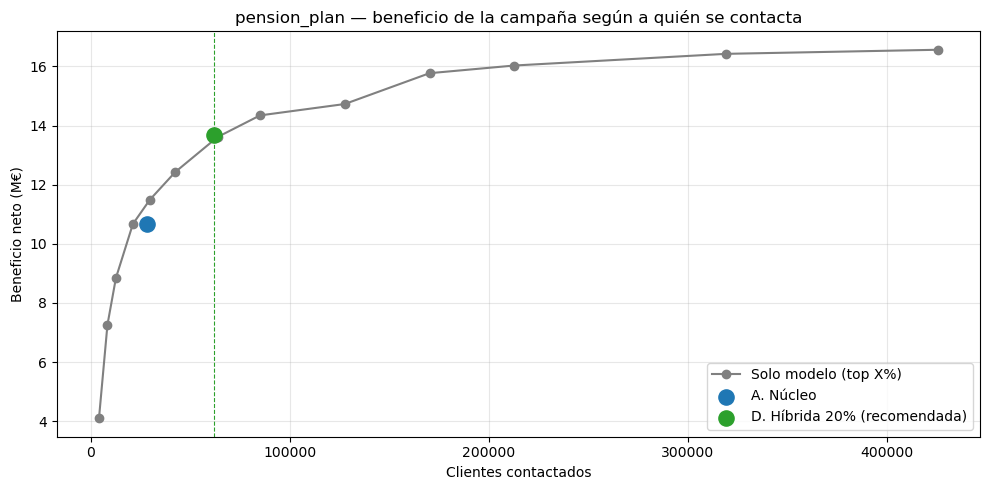

In [14]:
# Curva de beneficio por corte del modelo, con las estrategias A y D marcadas.
b = p["beneficio"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(b["clientes"], b["beneficio"] / 1e6, marker="o", color="grey", label="Solo modelo (top X%)")
ax.scatter(hib_a["contactos"], hib_a["beneficio"] / 1e6, s=120, color="tab:blue", zorder=5, label="A. Núcleo")
ax.scatter(hib_d["contactos"], hib_d["beneficio"] / 1e6, s=120, color="tab:green", zorder=5,
           label=f"D. Híbrida {TOP_RESTO}% (recomendada)")
ax.axvline(hib_d["contactos"], color="tab:green", ls="--", lw=0.8)
ax.set_xlabel("Clientes contactados")
ax.set_ylabel("Beneficio neto (M€)")
ax.set_title("pension_plan — beneficio de la campaña según a quién se contacta")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

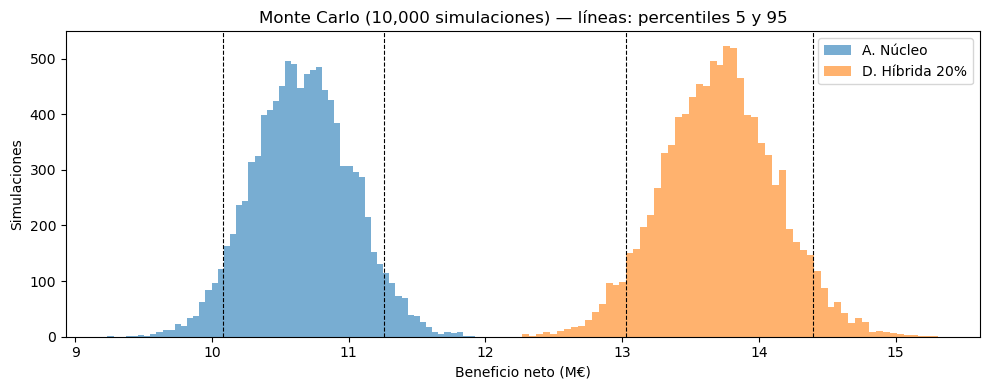

In [15]:
# Distribución del beneficio simulado: el intervalo del 90% es lo que se comunica a negocio.
fig, ax = plt.subplots(figsize=(10, 4))
for etiqueta, res in RESULTADOS_MC.items():
    ax.hist(res / 1e6, bins=60, alpha=0.6, label=etiqueta)
    p5, p95 = np.percentile(res, [5, 95]) / 1e6
    ax.axvline(p5, ls="--", lw=0.8, color="black")
    ax.axvline(p95, ls="--", lw=0.8, color="black")
ax.set_xlabel("Beneficio neto (M€)")
ax.set_ylabel("Simulaciones")
ax.set_title(f"Monte Carlo ({N_SIMULACIONES:,} simulaciones) — líneas: percentiles 5 y 95")
ax.legend()
plt.tight_layout()
plt.show()

Lectura. El primer gráfico compara las tres formas de elegir clientes. La línea gris es el beneficio de usar solo el modelo (top X %); los puntos son nuestras estrategias. A (solo núcleo) queda por debajo de la línea: con el mismo número de contactos, elegir solo por grupo rinde menos que elegir por nota. D (híbrida) queda prácticamente sobre la línea (13,70 M€ frente a 13,61 M€ del top 15 % con un número de contactos similar). Es decir, la híbrida mantiene la eficiencia del modelo y añade un criterio de negocio para decidir a qué grupos dirigirse y con qué mensaje. La curva sigue subiendo hasta el 100 % porque, con un coste de 0,50 € por contacto, cualquier venta adicional compensa; por eso la sección 10 analiza canales más caros.

El segundo gráfico muestra las 10.000 simulaciones Monte Carlo. Los intervalos del 90 % de A (10,1–11,3 M€) y D (13,0–14,4 M€) no se solapan: incluso en el escenario conservador, D supera al mejor escenario de A. Ninguna simulación da pérdidas.

## 12. Tablas para el simulador (Streamlit)

Toda la lógica pesada queda en este notebook; `simulador.py` solo lee estos ficheros ligeros y los combina. `papel_grupos.csv` le dice al simulador qué grupos son núcleo, intermedios o excluidos, así no hay que escribir nombres de grupo a mano en la app.

In [16]:
ruta_app = "../data/app/"
os.makedirs(ruta_app, exist_ok=True)

for nombre, q in PRODUCTOS.items():
    q["curva"].to_csv(ruta_app + f"curva_{nombre}.csv", index=False)
    pd.Series(q["margenes"], name="net_margin").to_csv(ruta_app + f"margenes_{nombre}.csv", index=False)
    q["por_grupo"].reset_index().to_csv(ruta_app + f"conversion_grupo_{nombre}.csv", index=False)

    sc_q = q["scoring"].merge(grupos, on="pk_cid", how="left")
    sc_q["nombre_grupo"] = sc_q["nombre_grupo"].fillna("Sin grupo")
    sc_q[["pk_cid", q["col_prob"], "nombre_grupo"]].to_csv(ruta_app + f"scoring_grupo_{nombre}.csv", index=False)

    q["validacion"].merge(grupos_abril, on="pk_cid", how="left").to_csv(ruta_app + f"validacion_grupo_{nombre}.csv", index=False)

hib.to_csv(ruta_app + "estrategias_hibridas.csv", index=False)
pg[["papel"]].reset_index().to_csv(ruta_app + "papel_grupos.csv", index=False)
print(sorted(os.listdir(ruta_app)))

['.DS_Store', 'conversion_grupo_em_acount.csv', 'conversion_grupo_pension_plan.csv', 'curva_em_acount.csv', 'curva_pension_plan.csv', 'estrategias_hibridas.csv', 'margenes_em_acount.csv', 'margenes_pension_plan.csv', 'papel_grupos.csv', 'scoring_grupo_em_acount.csv', 'scoring_grupo_pension_plan.csv', 'validacion_grupo_em_acount.csv', 'validacion_grupo_pension_plan.csv']


## 13. Resumen para negocio

Esta celda calcula las cifras clave. Las conclusiones de debajo se escriben a partir de ella.

In [17]:
mc_d = RESULTADOS_MC[f"D. Híbrida {TOP_RESTO}%"]
p5, p50, p95 = np.percentile(mc_d, [5, 50, 95])
margen_pp = margen_prod.xs(1364, level="product_ID")
margen_em = margen_prod.xs(4657, level="product_ID")

print("¿QUÉ PRODUCTO?")
print(f"  pension_plan: {p['margen_medio']:,.0f} € por venta ({margen_pp['pct_margen_total'].iloc[0]:.0f}% del margen total)"
      f" | em_acount: {PRODUCTOS['em_acount']['margen_medio']:,.0f} € por venta")
print("\n¿A CUÁNTOS?")
print(f"  {int(hib_d['contactos']):,} clientes ({hib_d['contactos'] / len(p['scoring']):.0%} de los {len(p['scoring']):,} elegibles)")
print("\n¿QUÉ GRUPOS?")
for g in NUCLEO:
    print(f"  Completo        : {g:32s} conversión {pg.loc[g, 'conversion_pct']:.2f}%")
for g in INTERMEDIO:
    print(f"  Top {TOP_RESTO}% modelo  : {g:32s} conversión {pg.loc[g, 'conversion_pct']:.2f}%")
excl = pg.loc[EXCLUIR]
print(f"  Fuera           : {', '.join(EXCLUIR)}"
      f" ({excl['clientes'].sum() / pg['clientes'].sum():.0%} de la base, conversión {excl['compras'].sum() / excl['clientes'].sum() * 100:.2f}%)")
print("\n¿CUÁNTO DINERO?")
print(f"  {p50/1e6:.1f} M€ en el mes; entre {p5/1e6:.1f} y {p95/1e6:.1f} M€ con un 90% de probabilidad"
      f" | P(pérdida) = {(mc_d < 0).mean():.1%} | break-even {conv_ext * p['margen_medio']:.0f} € por contacto")
print("\n¿QUÉ APORTA LA SEGMENTACIÓN?")
print(f"  Solo modelo (top 30%): {int(fila_c['clientes']):,} contactos → {fila_c['beneficio']/1e6:.1f} M€"
      f" | Híbrida: {int(hib_d['contactos']):,} contactos → {hib_d['beneficio']/1e6:.1f} M€")

¿QUÉ PRODUCTO?
  pension_plan: 5,976 € por venta (79% del margen total) | em_acount: 70 € por venta

¿A CUÁNTOS?
  62,220 clientes (15% de los 425,556 elegibles)

¿QUÉ GRUPOS?
  Completo        : Particulares con nómina          conversión 17.18%
  Completo        : Universitarios con nómina        conversión 13.27%
  Completo        : Particulares con tarjeta         conversión 1.76%
  Top 20% modelo  : Particulares básicos             conversión 0.78%
  Top 20% modelo  : TOP ahorradores                  conversión 0.60%
  Fuera           : Universitarios recién llegados, Sin producto, Universitarios inactivos (77% de la base, conversión 0.16%)

¿CUÁNTO DINERO?
  13.7 M€ en el mes; entre 13.0 y 14.4 M€ con un 90% de probabilidad | P(pérdida) = 0.0% | break-even 90 € por contacto

¿QUÉ APORTA LA SEGMENTACIÓN?
  Solo modelo (top 30%): 127,666 contactos → 14.7 M€ | Híbrida: 62,220 contactos → 13.7 M€


### Conclusiones

- **¿Qué producto?** pension_plan. Una venta deja de media 5.976 €; una em_acount, 70 €. pension_plan genera el 79 % del margen de la empresa, por eso la campaña se centra en él.
- **¿A cuántos?** 62.220 clientes, el 15 % de los 425.556 elegibles (clientes sin plan de pensiones).
- **¿Qué grupos?** Particulares con nómina, Universitarios con nómina y Particulares con tarjeta, completos (convierten al 17,2 %, 13,3 % y 1,8 %). De Particulares básicos y TOP ahorradores, solo los clientes que están en el 20 % con mejor nota del modelo. Universitarios recién llegados, Universitarios inactivos y Sin producto quedan fuera: son el 77 % de la base y convierten al 0,16 %.
- **¿Cuánto dinero?** 13,7 M€ en el mes, entre 13,0 y 14,4 M€ con un 90 % de probabilidad. Ninguna de las 10.000 simulaciones da pérdidas. La ampliación sobre el núcleo compensa mientras cada contacto cueste menos de 90 €.
- **Qué aporta la segmentación:** el modelo solo (top 30 %) necesita 127.666 contactos para 14,7 M€; la estrategia híbrida consigue 13,7 M€ con 62.220 contactos: el 93 % de las ventas con la mitad de contactos. Con un canal casi gratuito (email) el modelo solo deja algo más de dinero; a partir de unos 16 € por contacto, la híbrida es más rentable. La segmentación aporta además un criterio claro de a quién no contactar y perfiles para adaptar el mensaje.

**Limitaciones:** la conversión se mide en un solo mes (junio), los costes de campaña son supuestos y para cortes amplios las ventas pueden estar sobreestimadas, porque se aplica la conversión media a clientes cada vez menos propensos.

   streamlit run app/simulador.py